In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)


3.13.3 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2650
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


In [3]:
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

PART 1

In [6]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

In [7]:
print(oob_mask([0, 2, 2], 5))        # [False  True False  True  True]
print(oob_mask([], 3))               # [ True  True  True]
print(oob_mask(np.array([3, 0]), 4)) # [False  True  True False]

[False  True False  True  True]
[ True  True  True]
[False  True  True False]


In [8]:
bag.fit(X_train, y_train)

n = len(y_train)
oob_shares = [oob_mask(idx, n).mean() for idx in bag.estimators_samples_]

mean_oob = np.mean(oob_shares)
print("mean OOB share:      ", mean_oob)
print("mean in-bag share:   ", 1 - mean_oob)
print("formula (1-1/n)^n:   ", (1 - 1/n) ** n)
print("formula 1-(1-1/n)^n: ", 1 - (1 - 1/n) ** n)

mean OOB share:       0.3680653346019664
mean in-bag share:    0.6319346653980336
formula (1-1/n)^n:    0.3678210954587638
formula 1-(1-1/n)^n:  0.6321789045412363


In [10]:
votes = np.zeros((n, 2), dtype=int)

for t, idx in zip(bag.estimators_, bag.estimators_samples_):
    mask = oob_mask(idx, n)
    rows = np.where(mask)[0]
    pred = t.predict(X_train[rows])
    votes[rows, pred] += 1

oob_pred = votes.argmax(axis=1)
my_oob_acc = (oob_pred == y_train).mean()

print("my OOB accuracy:", my_oob_acc)
print("bag.oob_score_: ", bag.oob_score_)

my OOB accuracy: 0.9365683476054552
bag.oob_score_:  0.9365683476054552


In [12]:
from sklearn.model_selection import cross_validate

models = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}

fold_scores = {}
for name, model in models.items():
    fold_scores[name] = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

cv_table = pd.DataFrame(fold_scores).T
cv_table.columns = [f"fold {i+1}" for i in range(5)]
cv_table["mean"] = [np.mean(s) for s in fold_scores.values()]
cv_table["std"] = [np.std(s) for s in fold_scores.values()]
print(cv_table.round(4))

        fold 1  fold 2  fold 3  fold 4  fold 5    mean     std
tree    0.8986  0.8796  0.9033  0.8905  0.9032  0.8950  0.0090
bag     0.9334  0.9192  0.9398  0.9413  0.9206  0.9309  0.0093
rf      0.9445  0.9319  0.9572  0.9587  0.9333  0.9451  0.0114
lr      0.9334  0.9319  0.9445  0.9349  0.9349  0.9359  0.0044
bag_lr  0.9366  0.9303  0.9414  0.9333  0.9365  0.9356  0.0037


In [13]:
def paired(a, b):
    d = fold_scores[a] - fold_scores[b]
    inside = abs(d.mean()) <= d.std()
    print(f"{a} - {b}: folds {np.round(d, 4)}, mean {d.mean():.4f}, std {d.std():.4f}, inside the spread: {inside}")

paired("bag", "tree")
paired("rf", "tree")
paired("bag_lr", "lr")

bag - tree: folds [0.0349 0.0396 0.0365 0.0508 0.0175], mean 0.0358, std 0.0107, inside the spread: False
rf - tree: folds [0.046  0.0523 0.0539 0.0683 0.0302], mean 0.0501, std 0.0124, inside the spread: False
bag_lr - lr: folds [ 0.0032 -0.0016 -0.0032 -0.0016  0.0016], mean -0.0003, std 0.0023, inside the spread: True


In [14]:
rf.fit(X_train, y_train)

p = rf.score(X_test, y_test)
se = np.sqrt(p * (1 - p) / len(y_test))

print("rf oob_score_:     ", rf.oob_score_)
print("rf CV mean:        ", fold_scores["rf"].mean(), "(fold std:", fold_scores["rf"].std(), ")")
print("rf test accuracy p:", p, " SE:", se)
print("|oob - cv mean|:   ", abs(rf.oob_score_ - fold_scores["rf"].mean()))

rf oob_score_:      0.9444973041547733
rf CV mean:         0.9451321912811611 (fold std: 0.01137255199473839 )
rf test accuracy p: 0.9514747859181731  SE: 0.0066279773253566715
|oob - cv mean|:    0.0006348871263878175


## Part 1 — conclusions

**Out-of-bag share.** The mean out-of-bag share per tree is 0.3681, and the mean in-bag share is 0.6319. The formulas give (1 − 1/n)^n = 0.3678 and 1 − (1 − 1/n)^n = 0.6322, so the simulation matches the theory. My hand-made out-of-bag accuracy (0.93657) is identical to `bag.oob_score_` (0.93657).

**(a) Did bagging help?**

- **Decision tree: yes.** The paired fold difference bag − tree has mean +0.0358 and std 0.0107. The mean is larger than the std, so the difference is outside the fold spread, and bagging was better on all five folds (CV accuracy 0.8950 → 0.9309). The forest improves it further: rf − tree has mean +0.0501 and std 0.0124, also outside the spread (0.9451).
- **Logistic regression: no.** The difference bag_lr − lr has mean −0.0003 and std 0.0023. The mean is smaller than the std, so it is inside the fold spread, and these data cannot tell the two apart (0.9356 vs 0.9359). No winner is declared.
- **Mechanism.** A fully grown tree has high variance: a small change in the training sample changes the tree a lot. Bagging trains many trees on bootstrap samples and averages their votes, which reduces variance while the bias stays the same. Logistic regression is a stable, low-variance model, so models fitted on different bootstrap samples are almost identical and averaging them has little to remove. This is consistent with the fold std: 0.0090 for the tree and 0.0044 for logistic regression.

**(b) Is the out-of-bag score a fair stand-in for cross-validation?** For the forest, `oob_score_` = 0.9445 and the CV mean = 0.9451. The absolute difference is 0.0006, which is not larger than the std of the forest's five fold scores (0.0114), so the two numbers agree. The test accuracy is p = 0.9515 with standard error √(p(1 − p)/n_test) = 0.0066. The OOB score differs from it by 0.0070 (about 1.1 standard errors) and the CV mean by 0.0063 (about 1.0 standard error), so both estimates are close to the test accuracy. The out-of-bag score is a fair, free substitute for cross-validation here.

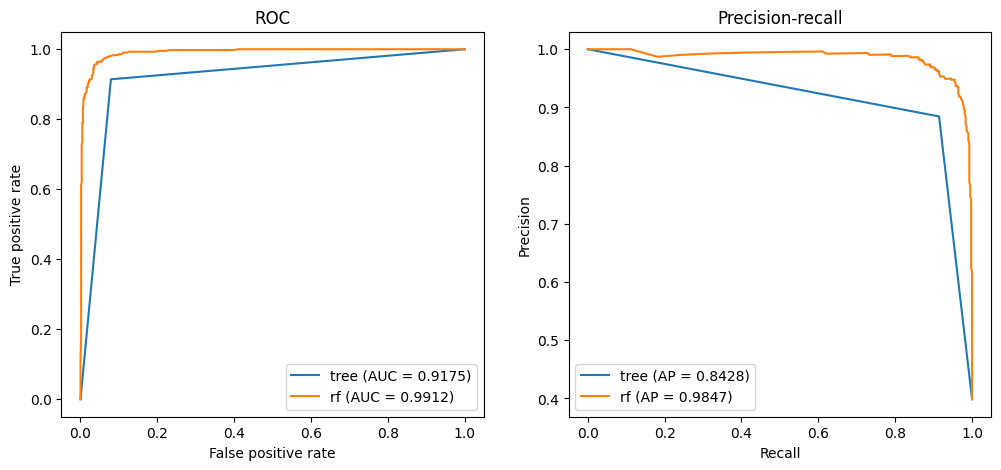

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, confusion_matrix)

tree_fit = clone(tree).fit(X_train, y_train)
scores = {"tree": tree_fit.predict_proba(X_test)[:, 1],
          "rf":   rf.predict_proba(X_test)[:, 1]}

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, s in scores.items():
    fpr_, tpr_, _ = roc_curve(y_test, s)
    ax[0].plot(fpr_, tpr_, label=f"{name} (AUC = {roc_auc_score(y_test, s):.4f})")
    prec_, rec_, _ = precision_recall_curve(y_test, s)
    ax[1].plot(rec_, prec_, label=f"{name} (AP = {average_precision_score(y_test, s):.4f})")

ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC"); ax[0].legend()
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall"); ax[1].legend()
plt.show()

In [16]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fpr, tpr, thr = roc_curve(y_train, oof, drop_intermediate=False)
ok = fpr <= 0.01                      # пороги, у которых out-of-fold FPR не больше 1 %
best_recall = tpr[ok].max()           # самый высокий recall среди них
t = thr[ok & (tpr == best_recall)].max()   # при ничьей берём наибольший порог

flagged = oof >= t
oof_fpr = (flagged & (y_train == 0)).sum() / (y_train == 0).sum()
oof_recall = (flagged & (y_train == 1)).sum() / (y_train == 1).sum()
print("threshold t:", t)
print("out-of-fold FPR:", oof_fpr, " recall:", oof_recall)

threshold t: 0.7666666666666667
out-of-fold FPR: 0.008966244725738396  recall: 0.7828162291169452


In [17]:
proba_test = rf.predict_proba(X_test)[:, 1]
pred = (proba_test >= t).astype(int)

cm = confusion_matrix(y_test, pred)
print(pd.DataFrame(cm, index=["true 0 (legit)", "true 1 (spam)"], columns=["pred 0", "pred 1"]))

tn, fp, fn, tp = cm.ravel()
print("precision:", tp / (tp + fp))
print("recall:   ", tp / (tp + fn))
print("FPR:      ", fp / (fp + tn))
print(f"legitimate test mails flagged: {fp} out of {fp + tn}")

                pred 0  pred 1
true 0 (legit)     628       4
true 1 (spam)       83     336
precision: 0.9882352941176471
recall:    0.801909307875895
FPR:       0.006329113924050633
legitimate test mails flagged: 4 out of 632


In [18]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")

top_perm = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False).head(5)
top_imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(5)
print("Permutation importance (test), top 5:\n", top_perm, "\n")
print("Impurity importance (train), top 5:\n", top_imp)

Permutation importance (test), top 5:
 word_freq_remove    0.021313
char_freq_exclam    0.017602
word_freq_hp        0.016270
char_freq_dollar    0.008944
word_freq_our       0.005423
dtype: float64 

Impurity importance (train), top 5:
 char_freq_exclam    0.113111
char_freq_dollar    0.097187
word_freq_remove    0.088800
word_freq_free      0.073362
word_freq_your      0.064709
dtype: float64


## Part 2 — conclusions

**Curves.** On the test split the forest is clearly better than the single tree: AUC 0.9912 vs 0.9175 and average precision 0.9847 vs 0.8428. The forest's ROC and precision-recall curves lie above the tree's over almost the whole range.

**Threshold chosen on the training split.** From the out-of-fold probabilities of the forest on the training split (the test split was not used), the highest recall with out-of-fold FPR ≤ 1 % is reached at t = 0.7667. At this threshold the out-of-fold FPR is 0.0090 and the recall is 0.7828.

**Applied once to the test split** (t was not changed afterwards):

| | pred 0 | pred 1 |
|---|---|---|
| true 0 (legitimate) | 628 | 4 |
| true 1 (spam) | 83 | 336 |

Precision 0.9882, recall 0.8019, FPR 0.0063. Four of 632 legitimate test mails were flagged as spam.

**Did the 1 % target hold?** Yes: the test FPR is 0.63 %, below 1 %. The price is recall: 83 of 419 spam mails (about 20 %) still get through. With only 632 legitimate test mails one mail changes the FPR by about 0.16 percentage points, so the observed FPR is itself uncertain (standard error about 0.3 percentage points). The out-of-fold FPR (0.90 %) was close to the limit, and the test value was lower, which is within what such a small count can do.

**Importances.** Top five by permutation importance on the test split: word_freq_remove (0.0213), char_freq_exclam (0.0176), word_freq_hp (0.0163), char_freq_dollar (0.0089), word_freq_our (0.0054). Top five by impurity importance: char_freq_exclam (0.1131), char_freq_dollar (0.0972), word_freq_remove (0.0888), word_freq_free (0.0734), word_freq_your (0.0647). The two lists share three features but rank them differently, and word_freq_hp is third by permutation but not in the impurity top five, while word_freq_free and word_freq_your are in the impurity top five but not in the permutation top five.

**Why they differ.** Impurity importance is the total decrease of impurity at all splits that use the feature, computed on the training data, so features that are used often (for example several correlated spam words such as free and your) collect a large value. Permutation importance shuffles one feature on the test split and measures the drop in accuracy. If other features carry similar information, shuffling one of them hurts little, so a feature like word_freq_free can have a large impurity importance but a small permutation importance. Conversely, word_freq_hp matters for the test accuracy (shuffling it costs accuracy) even though it does not collect the most impurity decrease in training. The two numbers answer different questions: how much the trees use a feature, and how much the predictions on unseen data depend on

In [19]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    preds = np.asarray(predictions, dtype=int)
    n_models, n_samples = preds.shape
    w = [1] * n_models if weights is None else list(weights)
    n_labels = int(preds.max()) + 1 if preds.size else 1
    counts = np.zeros((n_labels, n_samples))
    for m in range(n_models):                       # модели по порядку, начиная с model 0
        counts[preds[m], np.arange(n_samples)] += w[m]
    return counts.argmax(axis=0).astype(int)        # ничья -> наименьший лейбл; все нули -> 0

In [20]:
print(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]))        # [0 1 0]
print(hard_vote([[0, 1], [1, 0]]))                         # [0 0]
print(hard_vote([[0, 1], [1, 0]], weights=[1, 2]))         # [1 0]
print(hard_vote([[2, 0], [2, 1], [0, 1]]))                 # [2 1]

[0 1 0]
[0 0]
[1 0]
[2 1]


In [21]:
from sklearn.ensemble import VotingClassifier

fitted = [clone(m).fit(X_train, y_train) for _, m in members]
member_preds = np.array([m.predict(X_test) for m in fitted])     # форма (3, n_test)

mine = hard_vote(member_preds)
sk_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train).predict(X_test)
print("agreement with VotingClassifier:", (mine == sk_hard).mean())

names = [nm for nm, _ in members]
rows = []
for i in range(3):
    for j in range(i + 1, 3):
        rows.append((f"{names[i]} vs {names[j]}", (member_preds[i] != member_preds[j]).mean()))
print(pd.DataFrame(rows, columns=["pair", "disagreement"]))

agreement with VotingClassifier: 1.0
          pair  disagreement
0    lr vs knn      0.044719
1   lr vs tree      0.096099
2  knn vs tree      0.100856


In [22]:
vote_models = {"knn": knn,
               "hard": VotingClassifier(members, voting="hard"),
               "soft": VotingClassifier(members, voting="soft")}
for name, model in vote_models.items():
    fold_scores[name] = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

table3 = pd.DataFrame({k: fold_scores[k] for k in ["lr", "knn", "tree", "hard", "soft"]}).T
table3.columns = [f"fold {i+1}" for i in range(5)]
table3["mean"] = table3.mean(axis=1)
table3["std"] = [np.std(fold_scores[k]) for k in table3.index]
print(table3.round(4))

best_member = max(["lr", "knn", "tree"], key=lambda k: fold_scores[k].mean())
print("best member:", best_member)
paired("hard", best_member)
paired("soft", best_member)

      fold 1  fold 2  fold 3  fold 4  fold 5    mean     std
lr    0.9334  0.9319  0.9445  0.9349  0.9349  0.9359  0.0044
knn   0.9113  0.9128  0.9176  0.9190  0.9032  0.9128  0.0056
tree  0.8986  0.8796  0.9033  0.8905  0.9032  0.8950  0.0090
hard  0.9303  0.9287  0.9445  0.9397  0.9302  0.9347  0.0063
soft  0.9414  0.9303  0.9414  0.9413  0.9317  0.9372  0.0051
best member: lr
hard - lr: folds [-0.0032 -0.0032  0.      0.0048 -0.0048], mean -0.0013, std 0.0034, inside the spread: True
soft - lr: folds [ 0.0079 -0.0016 -0.0032  0.0063 -0.0032], mean 0.0013, std 0.0049, inside the spread: True


## Part 3 — conclusions

**Reproducing scikit-learn.** My `hard_vote` agrees with `VotingClassifier(voting="hard")` on 100 % of the test rows (fraction 1.0).

**Disagreement between members** (fraction of test rows with different predicted labels):

| pair | disagreement |
|---|---|
| lr vs knn | 0.0447 |
| lr vs tree | 0.0961 |
| knn vs tree | 0.1009 |

**Cross-validation** (same folds on the training split): lr 0.9359 ± 0.0044, knn 0.9128 ± 0.0056, tree 0.8950 ± 0.0090, hard voting 0.9347 ± 0.0063, soft voting 0.9372 ± 0.0051. The best member is lr (highest CV mean).

**Hard voting vs the best member.** The paired fold difference hard − lr has mean −0.0013 and std 0.0034. The absolute mean is smaller than the std, so the difference is inside the fold spread. No winner is declared: these data cannot separate hard voting from logistic regression.

**Soft voting vs the best member.** The paired fold difference soft − lr has mean +0.0013 and std 0.0049, again inside the fold spread. No winner is declared here either, even though soft voting has the highest mean of the five.

**Why voting does not clearly help here.** A vote gains when its members make different mistakes. Here lr and knn disagree on only 4.5 % of the test rows, so their mistakes overlap a lot, and the third member, the single tree, is clearly the weakest (0.8950 against 0.9359 for lr). When lr and knn agree they decide the hard vote regardless of the tree, so there is little left for the vote to fix. This is consistent with the numbers, but I did not test it directly.

In [23]:
from sklearn.ensemble import StackingClassifier

names = [nm for nm, _ in members]

# out-of-fold вероятности спама для каждого члена
oof_cols = [cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
            for _, m in members]
Z_train = np.column_stack(oof_cols)                 # форма (n_train, 3)
meta = LogisticRegression().fit(Z_train, y_train)

# для теста: члены обучены на всём train
fitted_members = [clone(m).fit(X_train, y_train) for _, m in members]
Z_test = np.column_stack([m.predict_proba(X_test)[:, 1] for m in fitted_members])
my_pred = meta.predict(Z_test)

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)

print("max |coef difference|:", np.abs(meta.coef_ - stack.final_estimator_.coef_).max())
print("test predictions identical:", np.array_equal(my_pred, stack.predict(X_test)))
print("my test accuracy:   ", (my_pred == y_test).mean())
print("stack.score (test): ", stack.score(X_test, y_test))

max |coef difference|: 0.0
test predictions identical: True
my test accuracy:    0.9476688867745005
stack.score (test):  0.9476688867745005


In [24]:
Z_naive = np.column_stack([clone(m).fit(X_train, y_train).predict_proba(X_train)[:, 1]
                           for _, m in members])
meta_naive = LogisticRegression().fit(Z_naive, y_train)

coef_table = pd.DataFrame({"naive": meta_naive.coef_[0], "out-of-fold": meta.coef_[0]}, index=names)
print(coef_table.round(4))

       naive  out-of-fold
lr    1.9671       4.3628
knn   1.7419       2.2485
tree  8.3288       1.4511


In [25]:
fold_scores["stack"] = cross_validate(
    StackingClassifier(members, LogisticRegression(), cv=cv),
    X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

table4 = pd.DataFrame({k: fold_scores[k] for k in ["stack", "soft", best_member]}).T
table4.columns = [f"fold {i+1}" for i in range(5)]
table4["mean"] = table4.mean(axis=1)
table4["std"] = [np.std(fold_scores[k]) for k in table4.index]
print(table4.round(4))

paired("stack", best_member)
paired("stack", "soft")

       fold 1  fold 2  fold 3  fold 4  fold 5    mean     std
stack  0.9414  0.9398  0.9461  0.9429  0.9286  0.9397  0.0060
soft   0.9414  0.9303  0.9414  0.9413  0.9317  0.9372  0.0051
lr     0.9334  0.9319  0.9445  0.9349  0.9349  0.9359  0.0044
stack - lr: folds [ 0.0079  0.0079  0.0016  0.0079 -0.0063], mean 0.0038, std 0.0056, inside the spread: True
stack - soft: folds [ 0.      0.0095  0.0048  0.0016 -0.0032], mean 0.0025, std 0.0043, inside the spread: True
